# Acousto-optic modulator

Phase-modulate light with a shear plate wave in an acousto-optic modulator.

**Question.** The {doc}`transducer page <transducer>` launches the shear plate wave
SH0 into a 360 nm film of x-cut lithium niobate and shows the strain it puts on two
waveguide ribs, in opposite phase. What does that strain do to the light the ribs
carry? The crystal's {term}`photoelastic tensor` turns strain into a change of the
optical permittivity, and the wave's own electric field adds an electro-optic part.
How much does the effective index of each arm move per volt on the fingers, how do
the two parts combine, and which {term}`voltage-length product` $V_\pi L$ does the
push-pull pair of arms reach? And how does that number move when the fingers' pitch
or the waveguide's position moves?

The device is the one of Ni, Bhave and Xu (arXiv 2606.05337): an acousto-optic
modulator on this stack, whose measured $V_\pi L$ was 1.004 V·cm at 0.842 GHz. This
page keeps the transducer page's eleven fingers and its two ribs, adds the light, and
computes the optical side: the shift of each arm's mode, per volt.

The chain from voltage to phase is two solves and one reading:

1. {py:class}`gfem.Piezoelectric`: the displacement and potential of the section at a
   band of frequencies, kept (`keep_fields=True`).
2. {py:func}`gfem.acousto_optic_shift`: one mode solve on each arm's
   {term}`optical window`, and the {term}`acousto-optic shift` of its effective
   index at every kept frequency, read from the acoustic section's fields.

**Assumptions.** The acoustic side is the transducer page's, with its assumptions. The
light adds:

| item | value |
| --- | --- |
| light | TE mode of the rib, $\lambda = 1550$ nm, the most propagating mode of the window |
| optical window | 6 µm wide and about 4 µm high around each rib: the film, the rib, 2 µm of oxide below and 2 µm of air above; no aluminium (the mode does not reach the fingers) |
| lithium niobate, optical | {py:func}`gfem.materials.lithium_niobate` at 1550 nm: indices from its dispersion law, and the clamped electro-optic tensor $r^S$ |
| photoelastic tensor | $p^E$ of Weis and Gaylord (1985): $p_{11} = -0.026$, $p_{12} = 0.090$, $p_{13} = 0.133$, $p_{14} = -0.075$, $p_{31} = 0.179$, $p_{33} = 0.071$, $p_{41} = -0.151$, $p_{44} = 0.146$ |
| oxide | silica from {py:func}`gfem.materials.silica` |
| position, aperture | windows on the ribs in the acoustic section's coordinates (offset 0); aperture 400 µm |

The photoelastic constants of the film are the bulk crystal's, and a published set
differs by tens of percent from another. The shift is linear in them, so a different set
scales the result with no new solve ({doc}`../recipes/acousto-optic-shift`).

In [1]:
import dataclasses
import time

import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import scipy.constants as sc
from aom_section import optical_window
from transducer_section import transducer_section

import gfem

um = 1e-6
tic = time.perf_counter()

## The acoustic side

{download}`transducer_section.py` and {download}`aom_section.py` build the meshes with
netgen. The transducer section is the transducer page's, with the same fingers, ribs,
frames and materials, and the same crystal frame: the crystal's $x$ axis is up, its $y$
axis runs along the film, and its $z$ axis is along the fingers, reversed. The
optical windows below use the same frame, so the stiffness, piezoelectric and
photoelastic tensors all rotate by one `axes`. The page solves the sweep once, at nine
frequencies from 0.80 to 0.90 GHz around the conductance peak, and keeps the fields:
the shift reads them at every frequency from one mode solve per arm.

In [2]:
section = transducer_section()  # 11 fingers at 2.2 um, two ribs, the damping frames

# lithium niobate in the crystal's frame (Warner et al. 1967); GPa and C/m^2
c11, c12, c13, c14, c33, c44 = 203, 53, 75, 9, 245, 60
C_LN = 1e9 * np.array(
    [
        [c11, c12, c13, c14, 0, 0],
        [c12, c11, c13, -c14, 0, 0],
        [c13, c13, c33, 0, 0, 0],
        [c14, -c14, 0, c44, 0, 0],
        [0, 0, 0, 0, c44, c14],
        [0, 0, 0, 0, c14, (c11 - c12) / 2],
    ]
)
e15, e22, e31, e33 = 3.7, 2.5, 0.2, 1.3
E_LN = np.array(
    [
        [0, 0, 0, 0, e15, -e22],
        [-e22, e22, 0, e15, 0, 0],
        [e31, e31, e33, 0, 0, 0],
    ]
)
# silicon is cubic: its 6x6 from c11, c12 and c44
s11, s12, s44 = 165.7e9, 63.9e9, 79.6e9
C_SI = np.zeros((6, 6))
C_SI[:3, :3] = s12
C_SI += np.diag([s11 - s12] * 3 + [s44] * 3)

# x-cut: crystal y along x (the wave), crystal x up, crystal z along -z
AXES = ((0, 1, 0), (1, 0, 0), (0, 0, -1))
Q = dict(mechanical_quality_factor=200.0)
ln = gfem.Material(
    eps_r=(44.0, 44.0, 29.0), axes=AXES, stiffness=C_LN,
    piezoelectric_tensor=E_LN, mass_density=4700.0, **Q,
)  # fmt: skip
sio2 = gfem.Material(
    eps_r=3.9, stiffness=gfem.isotropic_stiffness(73e9, 0.17), mass_density=2203.0, **Q
)
si = gfem.Material(stiffness=C_SI, mass_density=2329.0, **Q)
al = gfem.Material(
    stiffness=gfem.isotropic_stiffness(70e9, 0.35), mass_density=2700.0, **Q
)
model = gfem.Model(
    section.mesh,
    materials={
        "ln": ln, "ln_frame": ln, "box": sio2, "box_frame": sio2,
        "si": si, "si_frame": si, "signal": al, "ground": al, "air": gfem.Material(),
    },
    excluded={"mechanical": ["air"], "em": ["si", "si_frame"]},
)  # fmt: skip
frame = gfem.DampingFrame(["ln_frame", "box_frame", "si_frame"])  # loss factor 1.2

FREQUENCIES = np.linspace(0.80e9, 0.90e9, 9)
sweep = gfem.Piezoelectric(
    FREQUENCIES,
    terminals={"signal": "signal"},
    ground="ground",
    clamped="bottom",
    damping_frame=frame,
    keep_fields=True,
)
res = gfem.solve(model, sweep)
print(res)

PiezoelectricResult(terminals=['signal'], 9 frequencies 800-900 MHz, clamped capacitance per length in pF/m:
  signal:      686.8)


## The light

Each arm is a rib on the film, with oxide below and air above. The helper's
`optical_window(x)` meshes the 6 µm around a rib centred at $x$, in the acoustic
section's coordinates, as a thin slab for the mode solve; its regions are `"box"`,
`"slab"` (the 180 nm of film left under the rib), `"rib"` and `"air"`. The
{term}`photoelastic tensor` $p^E$ is a property of the optical crystal, as the
electro-optic tensor is: a 6 × 6 array, dimensionless, in the frame of the material's
`axes`, in the Voigt order of the strain and of $(\varepsilon_r^{-1})$ it
links, $\Delta(\varepsilon_r^{-1})_I = p_{IJ} S_J$ with the engineering strain
({doc}`../conventions`, "Photoelastic tensor"). The tensor of
{py:func}`gfem.materials.lithium_niobate` is the clamped $r^S$: the strain is counted
through $p$, the piezoelectric field through $r$, and a free $r^T$ would count the
strain twice.

In [3]:
WAVELENGTH = 1550e-9
F0 = sc.c / WAVELENGTH

# Weis and Gaylord (1985): p^E in the crystal's frame, Voigt xx yy zz yz xz xy
p11, p12, p13, p14, p31, p33, p41, p44 = (
    -0.026, 0.090, 0.133, -0.075, 0.179, 0.071, -0.151, 0.146,
)  # fmt: skip
P_LN = np.array(
    [
        [p11, p12, p13, p14, 0, 0],
        [p12, p11, p13, -p14, 0, 0],
        [p31, p31, p33, 0, 0, 0],
        [p41, -p41, 0, p44, 0, 0],
        [0, 0, 0, 0, p44, p41],
        [0, 0, 0, 0, p14, (p11 - p12) / 2],
    ]
)
LN_OPTICAL = dataclasses.replace(
    gfem.materials.lithium_niobate(frequency=F0, axes=AXES), photoelastic_tensor=P_LN
)
OXIDE = gfem.materials.silica(frequency=F0)
N_O, _, N_E = np.sqrt(LN_OPTICAL.eps_r)


def window_model(x_centre):
    # One arm's optical window; its mode is on the end face "front".
    materials = {"box": OXIDE, "slab": LN_OPTICAL, "rib": LN_OPTICAL}
    return gfem.Model(
        optical_window(x_centre),
        materials={**materials, "air": gfem.Material()},
        ports=[gfem.WavePort("arm", "front")],
    )


windows = [window_model(x) for x in section.arms[:, 0]]
print(windows[0].mesh)
print(f"n_o = {N_O:.4f}, n_e = {N_E:.4f}, oxide {np.sqrt(OXIDE.eps_r):.4f}")

Mesh(1526 nodes, 4383 tetrahedra, volumes=['box', 'air', 'slab', 'rib'], surfaces=['front', 'back'], length_unit='um', section_thickness=1e-07 m)
n_o = 2.2111, n_e = 2.1376, oxide 1.4440


{py:class}`gfem.PortMode` solves the window's guided modes, numbered from the most
propagating. The modulator uses the TE mode, polarized across the rib in the film's plane, along
$x$. The share of $|E_x|^2$ in $|E_x|^2 + |E_y|^2$ over the window tells which mode is
which:

In [4]:
x_a = section.arms[0, 0]
xw = x_a + np.linspace(-2.9, 2.9, 117) * um
yw = np.linspace(-1.5, 1.5, 61) * um
X, Y = np.meshgrid(xw, yw)
window_points = np.column_stack([X.ravel(), Y.ravel(), np.zeros(X.size)])  # on z = 0
found = gfem.solve(windows[0], gfem.PortMode("arm", F0, mode=1))
e = np.abs(np.asarray(found.e_field.at(window_points))[0]) ** 2
te_fraction = e[:, 0].sum() / (e[:, 0] + e[:, 1]).sum()
print(f"mode 1: n_eff {float(found.n_eff[0].real):.5f}, TE fraction {te_fraction:.3f}")

mode 1: n_eff 1.84009, TE fraction 0.998


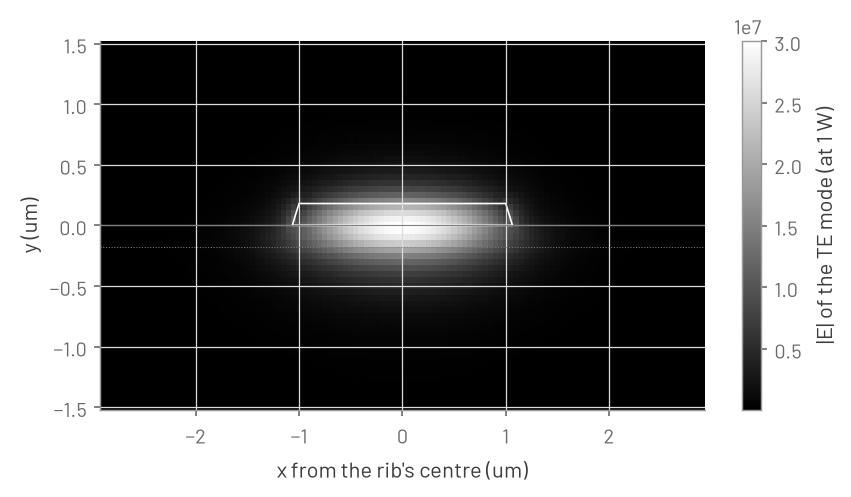

In [5]:
fig, ax = plt.subplots(figsize=(6.5, 3.2))
shape = (yw.size, xw.size)
image = ax.pcolormesh(
    (xw - x_a) / um, yw / um, np.sqrt(e.sum(axis=1)).reshape(shape), cmap="gray"
)
fig.colorbar(image, ax=ax, label="|E| of the TE mode (at 1 W)")
foot = 0.18 / np.tan(np.deg2rad(70.0))  # the rib's sidewalls lean at 70 degrees
rib = [(-1 - foot, 0), (1 + foot, 0), (1, 0.18), (-1, 0.18)]
ax.add_patch(plt.Polygon(rib, fill=False, ec="w", lw=0.8))
ax.axhline(0.0, color="gray", lw=0.5)
ax.axhline(-0.18, color="gray", lw=0.5, ls=":")
ax.set_xlabel("x from the rib's centre (um)")
ax.set_ylabel("y (um)");

Mode 1 is the TE mode: $n_\mathrm{eff} = 1.8401$, 99.8 % of its intensity along $x$.
`mode=1` picks it in the shift. Check the TE fraction for a window of your own: a wider
rib or a thicker film can reorder the modes.

{py:func}`gfem.acousto_optic_shift` takes the optical model, the piezoelectric result
and the optical frequency. It solves the port's mode once and weighs it, element by
element, against the change of permittivity the acoustic fields cause:

$$
\delta n_\mathrm{eff} = \sum_t W_t : \Delta\varepsilon_t, \qquad
\Delta\varepsilon_t = -\varepsilon_t\,(p_t \bar S_t + r_t \bar E_t)\,\varepsilon_t ,
$$

$W_t$ the mode's weight in triangle $t$ (its field at 1 W), $\bar S_t$ and
$\bar E_t$ the means of the engineering strain and of the electric field
$-\nabla\phi$ over the tetrahedron behind it, read in the acoustic section at the
tetrahedron's quadrature points. The shift of the arms at every kept frequency, per volt
on the fingers, costs one mode solve each: the acoustic fields are only read.

In [6]:
shifts = [
    gfem.acousto_optic_shift(
        w, res, port="arm", frequency=F0, terminal="signal", mode=1
    )
    for w in windows
]
a, b = shifts
print(a)
print(b)

AcoustoOpticShift(port 'arm', mode 1, terminal 'signal', 1.93414e+14 Hz, n_eff 1.840089, 9 acoustic frequencies 8e+08 to 9e+08 Hz, v_pi_l 0.0744747 to 0.114596 V m)
AcoustoOpticShift(port 'arm', mode 1, terminal 'signal', 1.93414e+14 Hz, n_eff 1.840090, 9 acoustic frequencies 8e+08 to 9e+08 Hz, v_pi_l 0.0748548 to 0.115456 V m)


Each shift is a complex array over the nine acoustic frequencies, a phasor. With the
fingers driven at $\mathrm{Re}(V e^{i\Omega t})$, the effective index of an arm is
$n(t) = n_\mathrm{eff} + \mathrm{Re}(\delta n\, V e^{i\Omega t})$, to first order in the
drive: $\delta n$ is `delta_n_eff_per_volt` at the acoustic frequency
$\Omega/2\pi$. It is the sum of two phasors, the photoelastic part and the
electro-optic part (`photoelastic_per_volt` and `electro_optic_per_volt`). The first
is the strain through $p$, the second the piezoelectric field through $r$.

In [7]:
dn_a, dn_b = (np.asarray(s.delta_n_eff_per_volt) for s in shifts)
pe_a, eo_a = np.asarray(a.photoelastic_per_volt), np.asarray(a.electro_optic_per_volt)
f_ghz = FREQUENCIES / 1e9
antiphase = np.degrees(np.angle(-dn_b / dn_a))  # 0 when the arms are in antiphase
ratio = eo_a / pe_a
i = 5  # 0.8625 GHz, nearest the conductance peak
print(f"at {f_ghz[i]:.4f} GHz, arm a, per volt:")
print(f"  photoelastic {pe_a[i]:.3e}, electro-optic {eo_a[i]:.3e}, total {dn_a[i]:.3e}")
print(f"|dn_b / dn_a| = {abs(dn_b[i] / dn_a[i]):.4f}")
print(
    f"the arms are in antiphase to within {abs(antiphase).max():.2f} deg over the band"
)
print(f"|EO / PE| between {abs(ratio).min():.3f} and {abs(ratio).max():.3f}")
opposite = np.degrees(np.angle(-ratio))  # 0 when EO and PE are of opposite sign
print(f"EO and PE are {opposite.min():+.0f} to {opposite.max():+.0f} deg from opposed")

at 0.8625 GHz, arm a, per volt:
  photoelastic -5.312e-06+1.177e-05j, electro-optic 2.549e-06-3.290e-06j, total -2.763e-06+8.482e-06j
|dn_b / dn_a| = 0.9940
the arms are in antiphase to within 0.27 deg over the band
|EO / PE| between 0.312 and 0.353
EO and PE are -6 to +22 deg from opposed


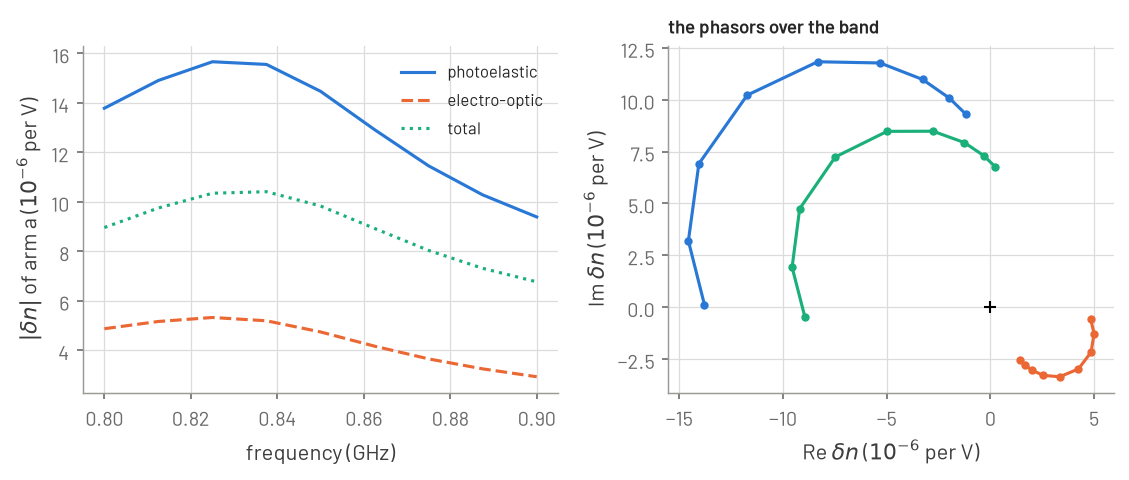

In [8]:
fig, (ax_a, ax_b) = plt.subplots(1, 2, figsize=(9, 3.0))
for part, label, style in (
    (pe_a, "photoelastic", "-"),
    (eo_a, "electro-optic", "--"),
    (dn_a, "total", ":"),
):
    ax_a.plot(f_ghz, 1e6 * np.abs(part), style, label=label)
ax_a.set_xlabel("frequency (GHz)")
ax_a.set_ylabel(r"$|\delta n|$ of arm a ($10^{-6}$ per V)")
ax_a.legend(fontsize=8)
ax_b.plot(0, 0, "k+")
for part, label in ((pe_a, "photoelastic"), (eo_a, "electro-optic"), (dn_a, "total")):
    z = 1e6 * part
    ax_b.plot(z.real, z.imag, "o-", ms=3, label=label)
ax_b.set_xlabel(r"Re $\delta n$ ($10^{-6}$ per V)")
ax_b.set_ylabel(r"Im $\delta n$ ($10^{-6}$ per V)")
ax_b.set_aspect("equal")
ax_b.set_title("the phasors over the band", fontsize=9);

The two arms respond alike. At 0.8625 GHz, near the conductance peak, arm a's shift is
$-2.8\times10^{-6} + 8.5\times10^{-6}i$ per volt, and arm b's has the same magnitude to
0.6 % and the opposite sign to 0.3° over the band: the transducer page's push-pull
strain carries over to the index. The rest of this section looks at one arm.

The photoelastic part leads. The electro-optic part is 0.31 to 0.35 of it in
magnitude, and the two phasors point between −6° and +22° from opposite directions: the
strain and the piezoelectric field of the same wave move the index against each other,
and the sum is about 0.7 of the strain's part alone. No experiment separates them, but
the calculation does: `photoelastic_per_volt` leaves the electro-optic tensor out, and
`electro_optic_per_volt` the photoelastic one. A model that counted the strain alone
would put the index change about 45 % high. The shift peaks near 0.83 GHz, below the
conductance peak at 0.865 GHz: the two need not coincide.

## Push-pull and the voltage the source sees

The arms are in antiphase, so a push-pull modulator wires them to add their phases.
Each arm alone needs $V_\pi L = \lambda/(2|\delta n|)$ per volt on the fingers, which
is `100 * a.v_pi_l` in V cm, and the pair needs

$$
V_\pi L = \frac{\lambda}{2\,|\delta n_a - \delta n_b|},
$$

half of an arm's. The voltage on the fingers is not the voltage a source puts in. A
source of impedance $Z_0 = 50$ Ω sends the fingers $V_\mathrm{IDT} = 2Z\,V_\mathrm{inc} /
(Z_L + Z_0)$ for an incident wave $V_\mathrm{inc}$, with $Z = 1/(W Y')$ the transducer's
impedance and $Z_L = Z + R_s$ its load with the fingers' series resistance. The product
per volt of incident wave is the one per volt on the fingers times $|(Z_L + Z_0) / (2Z)|$.

In [9]:
v_pi_l_idt = 100 * WAVELENGTH / (2 * np.abs(dn_a - dn_b))  # V cm per IDT volt

RHO_AL, W_FINGER, T_FINGER = 3.0e-8, 1.1e-6, 50e-9  # ohm m, m, m
APERTURE = 400e-6  # m
n_signal, n_ground = section.fingers
r_finger = RHO_AL * APERTURE / (W_FINGER * T_FINGER)
R_S = r_finger / 3 * (1 / n_signal + 1 / n_ground)  # the fingers' series resistance
y = np.asarray(res.admittance_per_length)[:, 0, 0]  # S/m
z_idt = 1 / (APERTURE * y)  # the transducer's own impedance, ohm
z_load = z_idt + R_S
refer = np.abs((z_load + 50.0) / (2 * z_idt))  # |V_incident / V_IDT|
v_pi_l_incident = v_pi_l_idt * refer  # V cm of incident wave

z = z_idt[i]
print(f"R_s = {R_S:.1f} ohm, Z at {f_ghz[i]:.4f} GHz = {z.real:.1f} {z.imag:+.1f}i ohm")
print(f"arm a alone: V_pi L = {100 * float(a.v_pi_l[i]):.2f} V cm per IDT volt")
print(
    f"push-pull: {v_pi_l_idt[i]:.2f} V cm per IDT volt, "
    f"{v_pi_l_incident[i]:.2f} V cm of incident wave"
)
for name, v in (("per IDT volt", v_pi_l_idt), ("incident", v_pi_l_incident)):
    k = int(np.argmin(v))
    print(f"lowest {name}: {v[k]:.2f} V cm at {f_ghz[k]:.4f} GHz")
print(f"|V_incident / V_IDT| between {refer.min():.2f} and {refer.max():.2f}")

R_s = 26.7 ohm, Z at 0.8625 GHz = 152.4 -436.0i ohm
arm a alone: V_pi L = 8.69 V cm per IDT volt
push-pull: 4.36 V cm per IDT volt, 2.32 V cm of incident wave
lowest per IDT volt: 3.73 V cm at 0.8375 GHz
lowest incident: 1.94 V cm at 0.8250 GHz
|V_incident / V_IDT| between 0.51 and 0.53


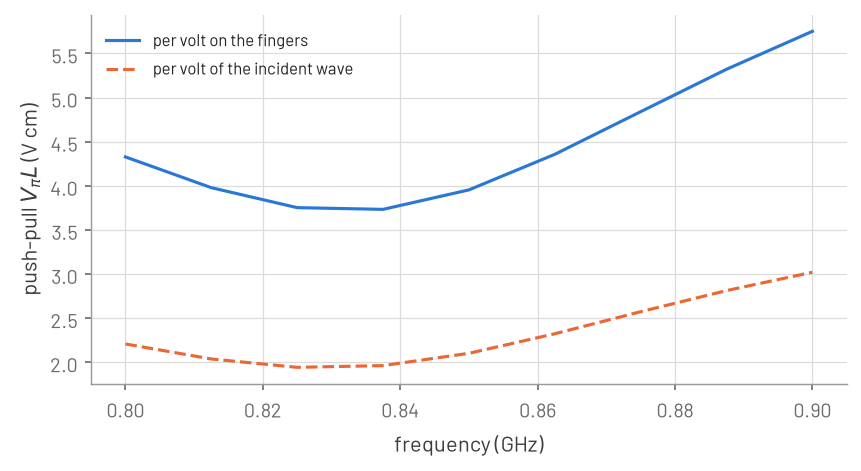

In [10]:
fig, ax = plt.subplots(figsize=(6.5, 3.2))
ax.plot(f_ghz, v_pi_l_idt, label="per volt on the fingers")
ax.plot(f_ghz, v_pi_l_incident, "--", label="per volt of the incident wave")
ax.set_xlabel("frequency (GHz)")
ax.set_ylabel(r"push-pull $V_\pi L$ (V cm)")
ax.legend(fontsize=8);

The pair needs 4.4 V cm per volt on the fingers at 0.8625 GHz, half of an arm's 8.7 V cm,
and its lowest value over the band is 3.7 V cm at 0.8375 GHz. The short transducer is
mostly a capacitor ($Z = 152 - 436i$ Ω), so the fingers see about twice the incident
wave's voltage, and the product per incident volt is lower: 1.9 V cm at its lowest,
0.825 GHz.

This transducer has eleven fingers and no reflectors, and launches a weak wave: the shifts
of the full-size device are about nine times larger. The measured $V_\pi L$ of Ni, Bhave
and Xu, 1.004 V·cm at 0.842 GHz, is of the full-size device, so this page's number is not
comparable to it and the page asserts nothing against it.

**The full-size device, an observation.** The same chain on the transducer page's
full-size section (20 signal and 19 ground fingers, 40 grounded strips on each side, the
two ribs 21 pitches apart, assumed counts; 25 µm lateral frames and a loss factor 0.6) has
1.14 million unknowns and is not run here. One run on 56 cores, with windows 8 µm wide and
5 µm high, gave $n_\mathrm{eff} = 1.8401$ in both arms, with shifts in antiphase to 0.1°
and an electro-optic part 0.29 to 0.32 of the photoelastic part, of opposite sign. At
0.8597 GHz the impedance is $Z = 40.9 + 0.1i$ Ω and $S_{11}$ dips to about −35 dB. The
push-pull $V_\pi L$ is 0.41 V cm per volt on the fingers at its lowest (0.8585 GHz) and
0.48 V cm per volt of incident wave at 0.861 GHz. The measured 1.004 V·cm is 2.1 times
higher, at a frequency 2 % lower. A cross-section has no finger ends, busbars or
diffraction across the aperture, and the finger counts, quality factor and photoelastic
constants are assumed: the page does not apportion the difference
({doc}`../verification`).

## The shift's exact derivative

How fast does the push-pull shift change with the design? Two parameters move it
without a remesh. The first is the transducer page's pitch stretch $\sigma$: a node map
that scales the finger set, and the ribs with it, about the left frame's inner edge,
through {py:meth}`gfem.Mesh.with_nodes`. The second is the shift's own
`offset`, the position of the optical windows relative to the acoustic section: the
acoustic fields are read at the optical points plus `offset`, a rigid move that leaves
the mode as it is. Here it carries two things: the ribs' move under the stretch, so that
the windows stay on them, $(\sigma - 1)(x_\mathrm{rib} - x_\mathrm{left})$ for each arm,
and a common slide of both windows along the film.

The objective is $|\delta n_a - \delta n_b|$ per volt at 0.8625 GHz, from a
single-frequency piezoelectric solve. `jax.value_and_grad` returns its value and both
derivatives from one solve and one pass over the nodes: the gradient reaches the pitch
through the fields' coefficients and the reading points' place in the moved mesh, and
the slide through the same reading. The two mode solves are held constant. The windows'
own geometry is not differentiable ({doc}`../recipes/acousto-optic-shift`).

In [11]:
x_left, x_right = section.interior  # the span between the lateral frames, m
nodes0 = jnp.asarray(section.mesh.nodes)
f_drive = FREQUENCIES[i]
one_frequency = gfem.Piezoelectric(
    f_drive, terminals={"signal": "signal"}, ground="ground", clamped="bottom",
    damping_frame=frame, keep_fields=True,
)  # fmt: skip


def stretch(nodes, sigma):
    # The pitch times sigma: scale the interior about the left frame's inner edge,
    # translate the right frame rigidly.
    x = nodes[:, 0]
    inside = jnp.clip(x, x_left, x_right)
    return nodes.at[:, 0].set(x - inside + x_left + sigma * (inside - x_left))


def push_pull(p):
    # |dn_a - dn_b| per volt at f_drive, with every pitch scaled by p[0] and the
    # waveguides slid by p[1] (m) along the acoustic section.
    sigma, slide = p
    moved = model.replace(mesh=section.mesh.with_nodes(stretch(nodes0, sigma)))
    result = gfem.solve(moved, one_frequency)
    dn = []
    for window, x in zip(windows, section.arms[:, 0], strict=True):
        # the ribs move with the fingers: a window at x reads at the rib's new place
        offset = jnp.stack([(sigma - 1) * (x - x_left) + slide, 0.0 * slide])
        shift = gfem.acousto_optic_shift(
            window, result, port="arm", frequency=F0, terminal="signal", mode=1,
            offset=offset,
        )  # fmt: skip
        dn.append(shift.delta_n_eff_per_volt[0])
    return jnp.abs(dn[0] - dn[1])


p0 = jnp.array([1.0, 0.0])
value, grad = jax.value_and_grad(push_pull)(p0)
print(f"|dn_a - dn_b| = {float(value):.4e} per V")
print(
    f"d/dsigma = {float(grad[0]):.4e}, d/dslide = {float(grad[1]):.4e} per V and per m"
)
slope = np.gradient(np.log(np.abs(dn_a - dn_b)), np.log(FREQUENCIES))[i]
print(
    f"d ln|dn| / d ln sigma = {float(grad[0] / value):+.2f}; "
    f"the sweep's d ln|dn| / d ln f = {slope:+.2f}"
)

|dn_a - dn_b| = 1.7788e-05 per V
d/dsigma = -1.1700e-04, d/dslide = -3.4714e-01 per V and per m
d ln|dn| / d ln sigma = -6.58; the sweep's d ln|dn| / d ln f = -6.98


In [12]:
H = (1e-6, 1e-12)  # the steps in sigma and in the slide (m)
fd = np.array(
    [
        (push_pull(p0 + h * e) - push_pull(p0 - h * e)) / (2 * h)
        for h, e in zip(H, jnp.eye(2), strict=True)
    ]
)
fd_error = np.abs(np.asarray(grad) / fd - 1)
print(f"central differences: {fd[0]:.4e} and {fd[1]:.4e}")
print(f"relative differences: {fd_error[0]:.1e} and {fd_error[1]:.1e}")

central differences: -1.1700e-04 and -3.4714e-01
relative differences: 8.8e-11 and 1.9e-08


The pitch's derivative says what a design loop would use. Stretching the pitch by 1 %,
22 nm, lowers the shift by 6.6 % and raises $V_\pi L$ by as much. Over a band this is
the sweep's own slope: the response depends on the product of the frequency and the
pitch to first order, so $\mathrm{d}\ln|\delta n| / \mathrm{d}\ln\sigma$ equals
$\mathrm{d}\ln|\delta n| / \mathrm{d}\ln f$ of the sweep, which the cell above prints
for comparison: −6.6 and −7.0. The slide's derivative is small: sliding both windows by
100 nm changes the shift by 0.2 %.

The check is a central difference of the same function, at a step of $10^{-6}$ in
$\sigma$ and $10^{-12}$ m in the slide. Its truncation is of order $(hk)^2/6$ for a field
varying as $e^{ikx}$, $k = 2\pi/4.4$ µm: below $10^{-12}$ for both steps. Its noise, that
of the two solves (about $10^{-14}$ of the value) divided by $2h$ times the derivative, is
$10^{-9}$ for the stretch and up to $5\times10^{-7}$ for the slide, below the printed
differences. The third error decides the slide's step: the strain is piecewise
polynomial with a jump across each element edge, and a reading point that crosses an edge
during the step adds the jump to the difference and nothing to the gradient. At a step of
10 pm the difference is already wrong, and the 1 pm step used here crosses no edge.

## Checks

| check | value | asserted |
| --- | --- | --- |
| TE fraction of mode 1 | 99.8 % | above 0.95 |
| effective index | 1.8401 | between 1.83 and 1.85 |
| arms in antiphase | 0.3° | to 1° |
| electro-optic part against the photoelastic one | opposite sign, magnitude 0.31 to 0.35 | real part of the ratio negative, magnitude between 0.25 and 0.40 |
| push-pull $V_\pi L$ | finite, positive | finite, positive |
| gradient against central differences | printed above | to $10^{-6}$ in the pitch and $10^{-5}$ in the slide, twenty times the slide's noise estimate |

## Limits

- **A cross-section.** The acoustic section is uniform along the fingers and the guide,
  so the arms' length is the aperture and the shift per length is uniform.
- **First order, mode held constant.** The shift is linear in the drive and in the
  tensors, from one mode solve, for a lossless section. At about $10^{-5}$ index change per
  volt the first order holds far beyond the drives of interest.
- **Photoelastic and electro-optic terms only.** The moving boundaries and the rotation
  of the crystal by the displacement are not counted. For this shear wave they vanish to
  first order, since $u_z$ moves no boundary; for Rayleigh or Lamb waves they are an
  approximation.
- **The tensors are the bulk crystal's.** $p^E$ is the literature's, and the film's can
  differ by tens of percent; $r$ must be the clamped $r^S$.
- **The windows hold no metal.** The mode does not reach the fingers.
- **The incident wave is a circuit's:** the lumped $R_s$, a 50 Ω source and one terminal.
- **The derivatives are of the shift at one acoustic frequency.** The optical model's
  nodes are not differentiable: a waveguide width needs a remesh and a finite difference.
- **The full-size device is an observation,** one run, not part of this page.

## Next

- {doc}`../recipes/acousto-optic-shift`: the shift from a piezoelectric result,
  push-pull and the incident wave, step by step.
- {doc}`transducer`: the acoustic side, the admittance and the pitch's derivative.
- {doc}`modulator`: the same crystal's electro-optic side, with a static field as the
  drive.
- {doc}`../recipes/piezoelectric-gradient`: the gradients with respect to the acoustic
  materials and node maps.
- {py:mod}`gfem.conventions`: the Voigt order, the sign of the loss and the phasor of
  the shift.

In [13]:
np.testing.assert_array_less(0.95, te_fraction)
np.testing.assert_array_less(1.83, float(a.n_eff))
np.testing.assert_array_less(float(a.n_eff), 1.85)
np.testing.assert_allclose(antiphase, 0.0, atol=1.0)
np.testing.assert_array_less(ratio.real, 0.0)
np.testing.assert_array_less(0.25, abs(ratio))
np.testing.assert_array_less(abs(ratio), 0.40)
np.testing.assert_array_less(0.0, v_pi_l_idt)
np.testing.assert_array_less(v_pi_l_idt, np.inf)
np.testing.assert_array_less(fd_error[0], 1e-6)
np.testing.assert_array_less(fd_error[1], 1e-5)
print(f"page run in {time.perf_counter() - tic:.0f} s")

page run in 125 s
